# 🧠 KV Cache i architektura Decoder-Only Transformer — Ćwiczenia

Notebook podzielony na **4 ćwiczenia**. Każde zawiera miejsca oznaczone `# TODO`, w których musisz dopisać **1–3 linijki kodu**.

Działa szybko na **darmowym CPU** w Colabie (i jeszcze szybciej na GPU T4).

| Ćwiczenie | Temat | Czas |
|-----------|-------|------|
| 1 | RMSNorm i SwiGLU — nowoczesne warstwy Transformera | 15 min |
| 2 | Maska przyczynowa (Causal Mask) — wizualizacja uwagi | 20 min |
| 3 | KV Cache — dlaczego generowanie bez niego zwalnia? | 25 min |
| 4 | (Bonus) Ile VRAM zjada KV Cache i jak ratuje nas GQA? | 10 min |

---

## Komórka 1: Importy i konfiguracja
Uruchom tę komórkę jako pierwszą.

In [2]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import time
import matplotlib.pyplot as plt
import seaborn as sns

# Ustawienie ziarna losowości dla powtarzalności wyników
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Używane urządzenie: {device.upper()}")

Używane urządzenie: CPU


---
## Ćwiczenie 1 – RMSNorm i SwiGLU: nowoczesne warstwy Transformera (15 min)

### Dlaczego to ważne?

W oryginalnym Transformerze (2017) używano **LayerNorm** do normalizacji i zwykłego **ReLU** jako funkcji aktywacji w sieci feed-forward. Nowoczesne modele (LLaMA, Mistral, Gemma) zamieniły je na:

- **RMSNorm** (Root Mean Square Normalization) — prostsza i szybsza wersja LayerNorm. Zamiast liczyć średnią *i* wariancję, liczy tylko pierwiastek ze średniej kwadratów. Dzięki temu jest ~10–15% szybsza, a działa równie dobrze.
- **SwiGLU** — bramkowana funkcja aktywacji, która zastępuje klasyczne `ReLU → Linear`. Jedna ścieżka decyduje "ile przepuścić" (bramka ze Swish), druga niesie informację. Wynik to ich iloczyn.

### Porównanie: LayerNorm vs RMSNorm

| | LayerNorm | RMSNorm |
|---|---|---|
| Centruje dane (odejmuje średnią)? | ✅ Tak | ❌ Nie |
| Skaluje przez odchylenie/RMS? | ✅ Tak (wariancja) | ✅ Tak (RMS) |
| Uczony parametr skalujący? | ✅ γ i β | ✅ tylko γ |
| Szybkość | Wolniejszy | **Szybszy** (~10-15%) |

### Twoje zadanie
Zaimplementuj `RMSNorm` i `SwiGLU` — zobaczysz, że to zaledwie kilka linijek matematyki.

In [4]:
# ==========================================
# ZADANIE 1A: Zaimplementuj RMSNorm
# Wzór: x / sqrt(średnia(x^2) + eps) * wagi
# ==========================================
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        # Oblicz pierwiastek ze średniej kwadratów (wzdłuż ostatniego wymiaru: dim=-1, keepdim=True)
        # Wskazówka: użyj x.pow(2).mean(dim=-1, keepdim=True) oraz torch.rsqrt() (odwrotność pierwiastka)
        rms = torch.rsqrt(x.pow(2).mean(dim=-1, keepdim=True)+self.eps)

        return x * rms * self.weight


# ==========================================
# ZADANIE 1B: Zaimplementuj SwiGLU
# Wzór: Swish(xW_gate) * (xW_up), a potem rzutowanie w dół W_down
# ==========================================
class SwiGLU(nn.Module):
    def __init__(self, dim, hidden_dim):
        super().__init__()
        self.w_gate = nn.Linear(dim, hidden_dim, bias=False)
        self.w_up   = nn.Linear(dim, hidden_dim, bias=False)
        self.w_down = nn.Linear(hidden_dim, dim, bias=False)

    def forward(self, x):
        # Przepuść x przez bramkę z funkcją F.silu (to inna nazwa na Swish)
        # i pomnóż przez drugą ścieżkę (self.w_up(x))
        gated = F.silu(self.w_gate(x), inplace=True)*self.w_up(x)

        return self.w_down(gated)


# Test poprawności:
x_test = torch.randn(2, 10, 64)
norm = RMSNorm(64)
ffn = SwiGLU(64, 128)
out = ffn(norm(x_test))
assert out.shape == (2, 10, 64), "Zły kształt wyjścia!"
print("✅ Zadanie 1 zaliczone! Kształt tensorów się zgadza.")

✅ Zadanie 1 zaliczone! Kształt tensorów się zgadza.


---
## Ćwiczenie 2 – Maska przyczynowa (Causal Mask) i wizualizacja uwagi (20 min)

### Dlaczego to ważne?

Mechanizm **Self-Attention** pozwala każdemu słowu "patrzeć" na wszystkie inne słowa w zdaniu. To świetnie działa w **enkoderze** (np. BERT), gdzie chcemy widzieć cały kontekst.

Ale w **dekoderze** (np. GPT, LLaMA) model **generuje tekst słowo po słowie**. Podczas przewidywania 4. słowa nie wolno mu podglądać 5., 6. itd. — bo one jeszcze nie istnieją!

**Maska przyczynowa (Causal Mask)** rozwiązuje ten problem: zeruje uwagę na przyszłe pozycje, wstawiając `-inf` przed softmaxem (co daje 0 po softmaxie).

```
Bez maski (Enkoder):          Z maską (Dekoder):
┌─────────────────┐           ┌─────────────────┐
│ 0.2  0.3  0.1  0.4 │       │ 1.0  0    0    0   │
│ 0.1  0.4  0.2  0.3 │       │ 0.4  0.6  0    0   │
│ 0.3  0.1  0.3  0.3 │  →    │ 0.2  0.3  0.5  0   │
│ 0.2  0.2  0.3  0.3 │       │ 0.1  0.2  0.3  0.4 │
└─────────────────┘           └─────────────────┘
```

### Twoje zadanie
Nałóż maskę na macierz wyników uwagi i porównaj wizualnie oba podejścia.

> **💡 Wskazówka:** Najpierw uruchom komórkę **bez** uzupełniania TODO — zobaczysz dwa identyczne wykresy. Dopiero po dopisaniu `masked_fill` prawy wykres zmieni się (zera powyżej przekątnej).

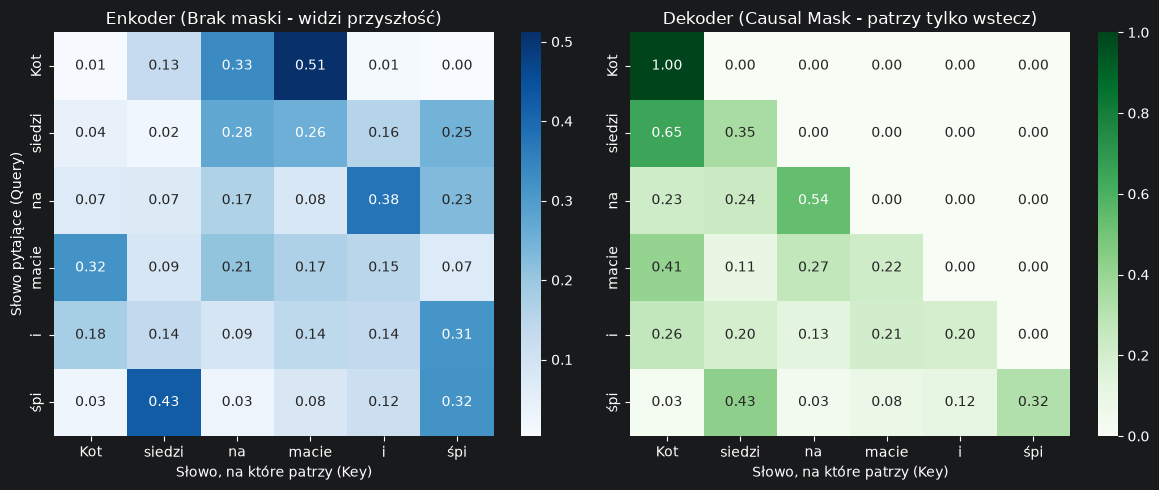

In [6]:
tokens = ["Kot", "siedzi", "na", "macie", "i", "śpi"]
seq_len = len(tokens)
d_k = 16

# Symulujemy macierze Query (Q) i Key (K) dla 6 słów
Q = torch.randn(seq_len, d_k)
K = torch.randn(seq_len, d_k)

# 1. Liczymy surowe wyniki uwagi: Q * K^T / sqrt(d_k)
scores = (Q @ K.T) / (d_k ** 0.5)

# ==========================================
# ZADANIE 2: Stwórz maskę przyczynową (Causal Mask)
# Chcemy, aby górny trójkąt macierzy (przyszłe słowa) miał wartość -inf
# ==========================================
# Stwórz macierz górnotrójkątną (jedynki powyżej głównej przekątnej, diagonal=1)
mask = torch.triu(torch.ones(seq_len, seq_len), diagonal=1).bool()

# Nałóż maskę na macierz 'scores' używając funkcji scores.masked_fill(mask, float('-inf'))
masked_scores = scores.masked_fill(mask, float('-inf'))

# Obliczamy prawdopodobieństwa przez Softmax
attn_no_mask = F.softmax(scores, dim=-1)
# Po uzupełnieniu zamień poniżej 'scores' na 'masked_scores':
attn_with_mask = F.softmax(masked_scores if masked_scores is not None else scores, dim=-1)

# Wizualizacja
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(attn_no_mask.detach().numpy(), xticklabels=tokens, yticklabels=tokens, annot=True, fmt=".2f", cmap="Blues", ax=axes[0])
axes[0].set_title("Enkoder (Brak maski - widzi przyszłość)")
axes[0].set_ylabel("Słowo pytające (Query)")
axes[0].set_xlabel("Słowo, na które patrzy (Key)")

sns.heatmap(attn_with_mask.detach().numpy(), xticklabels=tokens, yticklabels=tokens, annot=True, fmt=".2f", cmap="Greens", ax=axes[1])
axes[1].set_title("Dekoder (Causal Mask - patrzy tylko wstecz)")
axes[1].set_xlabel("Słowo, na które patrzy (Key)")
plt.tight_layout()
plt.show()

---
## Ćwiczenie 3 – Eksperyment z KV Cache: Dlaczego bez niego model zwalnia? (25 min)

### Dlaczego to ważne?

Kiedy model generuje tekst token po tokenie, w naiwnym podejściu **przelicza Q, K, V dla całej dotychczasowej sekwencji** przy każdym nowym tokenie. To oznacza:
- Token 1: oblicz attention dla 1 tokena
- Token 2: oblicz attention dla 2 tokenów (ponownie licząc K, V dla tokena 1!)
- Token 100: oblicz attention dla 100 tokenów (ponownie licząc K, V dla tokenów 1–99!)

To daje **złożoność kwadratową** O(n²) — im dłuższy tekst, tym coraz wolniej.

**KV Cache** rozwiązuje to sprytnie: skoro K i V dla starych tokenów się nie zmieniają (wagi modelu są zamrożone podczas inferencji), to wystarczy je **zapamiętać** i przy każdym nowym tokenie:
1. Obliczyć Q, K, V **tylko** dla tego jednego nowego tokena
2. **Dokleić** nowe K i V do zapamiętanej historii
3. Policzyć attention nowego Q wobec całej historii K, V

To daje **złożoność liniową** O(n)!

### Twoje zadanie
Zaimplementuj doklejanie nowych K i V do historii w metodzie `forward_with_cache`.

> **💡 Pytanie do dyskusji:** Spójrz na `forward_with_cache` — nie ma tam maski przyczynowej! Dlaczego podczas generowania z KV Cache **nie musimy** jej używać? Zastanów się zanim przejdziesz dalej.

In [9]:
class SimpleAttentionWithKVCache(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        self.d_model = d_model
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)

    def forward_no_cache(self, x_full_sequence):
        """
        Naiwne podejście: w każdym kroku przeliczamy Q, K, V dla CAŁEJ dotychczasowej historii!
        x_full_sequence ma kształt: [1, aktualna_dlugosc_tekstu, d_model]
        """
        Q = self.W_q(x_full_sequence)
        K = self.W_k(x_full_sequence)
        V = self.W_v(x_full_sequence)

        seq_len = x_full_sequence.size(1)
        mask = torch.triu(torch.ones(seq_len, seq_len, device=x_full_sequence.device), diagonal=1).bool()

        scores = (Q @ K.transpose(-2, -1)) / (self.d_model ** 0.5)
        scores = scores.masked_fill(mask, float('-inf'))
        attn = F.softmax(scores, dim=-1)
        out = attn @ V
        # Zwracamy tylko ostatni (nowo wygenerowany) wektor
        return out[:, -1:, :]

    def forward_with_cache(self, x_new_token, kv_cache=None):
        """
        Podejście z KV Cache: wchodzimy TYLKO z najnowszym tokenem [1, 1, d_model]!
        Poprzednie K i V wyciągamy z pamięci (kv_cache).
        """
        # Liczymy Q, K, V TYLKO dla tego jednego nowego tokenu
        q_new = self.W_q(x_new_token)
        k_new = self.W_k(x_new_token)
        v_new = self.W_v(x_new_token)

        if kv_cache is not None:
            k_past, v_past = kv_cache
            # ==========================================
            # ZADANIE 3: Doklej nowe k_new i v_new do historii (k_past, v_past)
            # Użyj torch.cat([stare, nowe], dim=1)
            # ==========================================
            K = torch.cat([k_past, k_new], dim=1)
            V = torch.cat([v_past, v_new], dim=1)
        else:
            K, V = k_new, v_new

        # Zauważ: nie potrzebujemy nawet maski przyczynowej!
        # q_new to ostatni token, więc ma prawo patrzeć na wszystkie dotychczasowe K i V.
        scores = (q_new @ K.transpose(-2, -1)) / (self.d_model ** 0.5)
        attn = F.softmax(scores, dim=-1)
        out = attn @ V

        # Zwracamy wynik oraz zaktualizowany KV Cache na kolejny krok
        return out, (K, V)

### 💬 Odpowiedź na pytanie dyskusyjne

<details>
<summary><b>Kliknij, żeby zobaczyć odpowiedź</b> (najpierw spróbuj sam!)</summary>

Maska przyczynowa nie jest potrzebna, bo wchodzimy **tylko z jednym, najnowszym wektorem `q_new`** — na samym końcu sekwencji. Ten token ma pełne prawo widzieć **całą przeszłość** zapisaną w K i V. Nie ma żadnych "przyszłych" tokenów do zamaskowania!

Podczas **treningu** maska jest potrzebna, bo przetwarzamy całą sekwencję naraz i każda pozycja musi "udawać", że nie widzi tego, co po niej.

</details>

---
## Benchmark i wykres prędkości

**Uruchom po zrobieniu Zadania 3.** Generujemy 600 tokenów obiema metodami i porównujemy czas.

Spodziewany wynik:
- 🔴 **Bez KV Cache** — krzywa rośnie kwadratowo (coraz wolniej z każdym tokenem)
- 🟢 **Z KV Cache** — krzywa rośnie liniowo (stały czas na token)

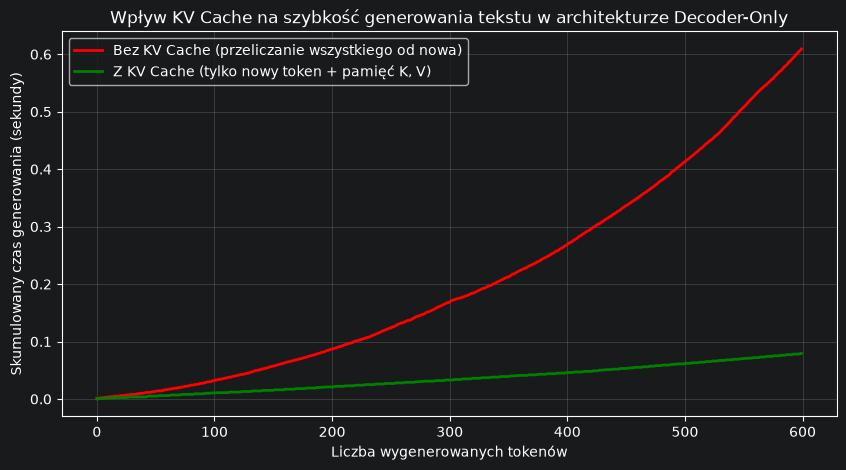

Czas całkowity BEZ KV Cache: 0.609 s
Czas całkowity Z KV Cache:   0.079 s
Przyspieszenie:              7.7x szybciej!


In [10]:
d_model = 256
num_steps = 600
model = SimpleAttentionWithKVCache(d_model).to(device)
model.eval()

# 1. Pomiar BEZ KV Cache
times_no_cache = []
sequence = torch.randn(1, 1, d_model, device=device)

with torch.no_grad():
    start = time.time()
    for step in range(num_steps):
        out = model.forward_no_cache(sequence)
        # Doklejamy nowy wygenerowany token do sekwencji
        sequence = torch.cat([sequence, out], dim=1)
        times_no_cache.append(time.time() - start)

# 2. Pomiar Z KV Cache
times_with_cache = []
current_token = torch.randn(1, 1, d_model, device=device)
kv_cache = None

with torch.no_grad():
    start = time.time()
    for step in range(num_steps):
        current_token, kv_cache = model.forward_with_cache(current_token, kv_cache)
        times_with_cache.append(time.time() - start)

# Rysowanie wykresu
plt.figure(figsize=(10, 5))
plt.plot(times_no_cache, label="Bez KV Cache (przeliczanie wszystkiego od nowa)", color="red", linewidth=2)
plt.plot(times_with_cache, label="Z KV Cache (tylko nowy token + pamięć K, V)", color="green", linewidth=2)
plt.xlabel("Liczba wygenerowanych tokenów")
plt.ylabel("Skumulowany czas generowania (sekundy)")
plt.title("Wpływ KV Cache na szybkość generowania tekstu w architekturze Decoder-Only")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Czas całkowity BEZ KV Cache: {times_no_cache[-1]:.3f} s")
print(f"Czas całkowity Z KV Cache:   {times_with_cache[-1]:.3f} s")
print(f"Przyspieszenie:              {times_no_cache[-1] / times_with_cache[-1]:.1f}x szybciej!")

---
## Ćwiczenie 4 (Bonus) – Ile pamięci VRAM zjada KV Cache i jak ratuje nas GQA? (10 min)

### Dlaczego to ważne?

KV Cache przyspiesza generowanie, ale ma swoją **cenę: pamięć VRAM**. Dla każdej warstwy modelu musimy przechowywać macierze K i V dla **każdego wygenerowanego tokena**. Przy dużych modelach (70B+ parametrów) i długich kontekstach (32k+ tokenów) to mogą być **dziesiątki gigabajtów**!

### Jak sobie z tym radzą nowoczesne modele?

Klasyczny mechanizm **Multi-Head Attention (MHA)** ma osobne K i V dla każdej głowicy uwagi (np. 64 głowice). To generuje ogromny KV Cache.

Rozwiązanie to **Grouped Query Attention (GQA)** — zamiast osobnych K, V dla każdej głowicy, kilka głowic **dzieli** te same K i V:

```
MHA (Multi-Head Attention):     GQA (Grouped Query Attention):
Q₁ → K₁, V₁                    Q₁ ─┐
Q₂ → K₂, V₂                    Q₂ ─┤→ K₁, V₁  (współdzielone!)
Q₃ → K₃, V₃                    Q₃ ─┘
Q₄ → K₄, V₄                    Q₄ ─┐
Q₅ → K₅, V₅                    Q₅ ─┤→ K₂, V₂  (współdzielone!)
Q₆ → K₆, V₆                    Q₆ ─┘

6 par K,V w cache               2 pary K,V w cache → 3x mniej pamięci!
```

Np. LLaMA-3 70B używa 64 głowic Q, ale tylko **8 głowic KV** (GQA) — oszczędność 8x!

### Twoje zadanie
Napisz wzór na rozmiar KV Cache i oblicz, ile VRAM potrzeba dla MHA vs GQA.

In [11]:
def oblicz_rozmiar_kv_cache_gb(liczba_warstw, liczba_glowic_kv, wymiar_glowicy, dlugosc_kontekstu, bajty_na_parametr=2):
    """
    Oblicza rozmiar KV Cache w gigabajtach (GB) dla pojedynczej rozmowy (batch_size=1).
    bajty_na_parametr = 2 dla formatu FP16 / BF16.
    Pamiętaj: przechowujemy zarówno K, jak i V (stąd mnożenie przez 2 na początku!).
    """
    # Pomnóż przez siebie: 2 (bo K i V) * warstwy * głowice_kv * wymiar_glowicy * kontekst * bajty
    liczba_bajtow = 2*liczba_warstw*liczba_glowic_kv*wymiar_glowicy*dlugosc_kontekstu*bajty_na_parametr

    return liczba_bajtow / (1024 ** 3)

# Parametry zbliżone do dużego modelu (np. Llama-3 70B przy długim kontekście 32k tokenów)
warstwy = 80
wymiar_glowicy = 128
kontekst = 32768  # 32k tokenów

# Po uzupełnieniu:
mha_gb = oblicz_rozmiar_kv_cache_gb(warstwy, liczba_glowic_kv=64, wymiar_glowicy=wymiar_glowicy, dlugosc_kontekstu=kontekst)
gqa_gb = oblicz_rozmiar_kv_cache_gb(warstwy, liczba_glowic_kv=8,  wymiar_glowicy=wymiar_glowicy, dlugosc_kontekstu=kontekst)

print(f"Rozmiar KV Cache dla klasycznego MHA (64 głowice KV): {mha_gb:.2f} GB VRAM!")
print(f"Rozmiar KV Cache dla nowoczesnego GQA (8 głowic KV):  {gqa_gb:.2f} GB VRAM!")
print(f"Oszczędność dzięki GQA: {mha_gb / gqa_gb:.0f}x mniej pamięci!")

Rozmiar KV Cache dla klasycznego MHA (64 głowice KV): 80.00 GB VRAM!
Rozmiar KV Cache dla nowoczesnego GQA (8 głowic KV):  10.00 GB VRAM!
Oszczędność dzięki GQA: 8x mniej pamięci!
